<a href="https://colab.research.google.com/github/alansanthosh042005-cyber/customer-churn-predictor/blob/main/Customer_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Libaries

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Dataset

In [29]:
data=pd.read_csv("Churn_Data.csv")

In [30]:
data

,CustomerID,Age,Gender,Location,SubscriptionType,ContractLength,MonthlyBill,TotalDataUsageGB,CustomerSupportCalls,Churn
0,CUST-10000,56,Male,Houston,Standard,1-Year,83.93,433,8,No
1,CUST-10001,69,Male,Miami,Basic,1-Year,87.21,100,8,No
2,CUST-10002,46,Female,Miami,Premium,Monthly,94.19,151,1,Yes
3,CUST-10003,32,Female,Los Angeles,Standard,1-Year,99.30,51,3,No
4,CUST-10004,60,Male,New York,Standard,Monthly,87.15,258,0,No
...,...,...,...,...,...,...,...,...,...,...
4995,CUST-14995,67,Female,New York,Standard,1-Year,44.71,91,4,No
4996,CUST-14996,39,Female,Houston,Standard,Monthly,52.67,103,2,Yes
4997,CUST-14997,46,Female,Miami,Standard,Monthly,63.08,330,4,Yes
4998,CUST-14998,39,Female,Houston,Premium,Monthly,36.26,352,9,Yes


In [31]:
data.head()

,CustomerID,Age,Gender,Location,SubscriptionType,ContractLength,MonthlyBill,TotalDataUsageGB,CustomerSupportCalls,Churn
0,CUST-10000,56,Male,Houston,Standard,1-Year,83.93,433,8,No
1,CUST-10001,69,Male,Miami,Basic,1-Year,87.21,100,8,No
2,CUST-10002,46,Female,Miami,Premium,Monthly,94.19,151,1,Yes
3,CUST-10003,32,Female,Los Angeles,Standard,1-Year,99.30,51,3,No
4,CUST-10004,60,Male,New York,Standard,Monthly,87.15,258,0,No


In [32]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   CustomerID            5000 non-null   object 
 1   Age                   5000 non-null   int64  
 2   Gender                5000 non-null   object 
 3   Location              5000 non-null   object 
 4   SubscriptionType      5000 non-null   object 
 5   ContractLength        5000 non-null   object 
 6   MonthlyBill           5000 non-null   float64
 7   TotalDataUsageGB      5000 non-null   int64  
 8   CustomerSupportCalls  5000 non-null   int64  
 9   Churn                 5000 non-null   object 
dtypes: float64(1), int64(3), object(6)
memory usage: 390.8+ KB


In [33]:
print(f"\nNumber of duplicate rows: {data.duplicated().sum()}")


Number of duplicate rows: 0


In [34]:
data.drop_duplicates(inplace=True) #it remove duplicates

In [35]:
data = data.drop("CustomerID", axis=1) #we don't need unessary feactures.

In [36]:
categorical_columns = ["Gender", "Location", "SubscriptionType", "ContractLength"]

###Apply Label Encoding to convert text categories into numerical values

In [37]:
encoder = LabelEncoder()
for col in categorical_columns:
    data[col] = encoder.fit_transform(data[col])

###Data after cleaning process

In [38]:
display(data.head())

,Age,Gender,Location,SubscriptionType,ContractLength,MonthlyBill,TotalDataUsageGB,CustomerSupportCalls,Churn
0,56,1,1,2,0,83.93,433,8,No
1,69,1,3,0,0,87.21,100,8,No
2,46,0,3,1,2,94.19,151,1,Yes
3,32,0,2,2,0,99.30,51,3,No
4,60,1,4,2,2,87.15,258,0,No


#Feature Scaling and Data Splitting

##Features (X) and Target (y)

In [39]:
X = data.drop("Churn", axis=1)
y = data["Churn"]

##Scale the features

In [40]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

##Split into Training and Testing stes

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

##After Training

In [42]:
print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")

Training data shape: (4000, 8)
Testing data shape: (1000, 8)


#Model Training and Evaluation

##Map 'Yes' to 1 and 'No' to 0

In [43]:
y = data["Churn"].map({'Yes': 1, 'No': 0})

In [44]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

##The models

In [45]:
model1 = LogisticRegression(max_iter=1000, solver='liblinear')
model2 = DecisionTreeClassifier(random_state=42)
model3 = SVC()

In [46]:
models = {
    "Logistic Regression": model1,
    "Decision Tree": model2,
    "Support Vector Machine": model3
}

##Train and evaluate the models

In [47]:
results = []

In [48]:
for name, model in models.items():
    model.fit(X_train, y_train) #model train
    y_pred = model.predict(X_test) #predict on test
    accuracy = accuracy_score(y_test, y_pred) #calculate matrix
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    #store result
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

##Result

In [49]:
results_df = pd.DataFrame(results)

In [50]:
display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.687,0.681927,0.687,0.680657
1,Decision Tree,0.601,0.600847,0.601,0.600923
2,Support Vector Machine,0.695,0.690379,0.695,0.689041


#Confusion matrix & Classification report

##Logistic Regression model

In [52]:
best_model = models["Logistic Regression"]
y_pred_lr = best_model.predict(X_test)

##Confusion Matrix

In [53]:
cm = confusion_matrix(y_test, y_pred_lr)

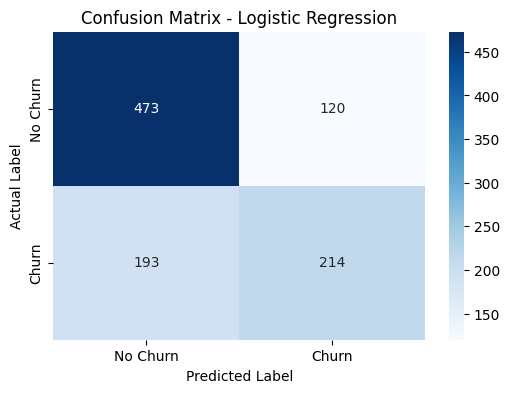

In [54]:
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

##Result

In [55]:
print(classification_report(y_test, y_pred_lr, target_names=['No Churn', 'Churn']))

              precision    recall  f1-score   support

    No Churn       0.71      0.80      0.75       593
       Churn       0.64      0.53      0.58       407

    accuracy                           0.69      1000
   macro avg       0.68      0.66      0.66      1000
weighted avg       0.68      0.69      0.68      1000



#Hyperparameter Tuning & Custom Predictions

##The parameter grid for KNN

In [56]:
parameterGrid = {
    'n_neighbors': list(range(1, 21)),
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

##GridSearchCV

In [61]:
grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=parameterGrid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

##Fit the grid search to the training data

In [62]:
grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12,
                                         13, 14, 15, 16, 17, 18, 19, 20],
                         'p': [1, 2], 'weights': ['uniform', 'distance']},
             scoring='accuracy')

##Display the best parameters and cross-validation score

In [65]:
print("Best Parameters:", grid.best_params_)
print("Best Accuracy: {:.2f}%".format(grid.best_score_ * 100))

Best Parameters: {'n_neighbors': 17, 'p': 1, 'weights': 'distance'}
Best Accuracy: 64.88%


##Extract the best model

In [66]:
best_knn_model = grid.best_estimator_

##Make a custom prediction on new scaled data

[Age, Gender, Location, SubscriptionType, ContractLength, MonthlyBill, TotalDataUsageGB, CustomerSupportCalls]

In [67]:
test_input = np.array([[0.5, 0.2, 0.8, 0.1, 0.9, 0.4, 0.7, 0.3]])
test_output = best_knn_model.predict(test_input)

##Map the numerical output back to a readable label

In [68]:
prediction_label = "Churn" if test_output[0] == 1 else "No Churn"

In [69]:
print(f"Test Input (Scaled): {test_input[0]}")
print(f"Predicted Output: {test_output[0]} ({prediction_label})")

Test Input (Scaled): [0.5 0.2 0.8 0.1 0.9 0.4 0.7 0.3]
Predicted Output: 0 (No Churn)
